In [1]:
import numpy as np
import glob
from sklearn.model_selection import train_test_split
import time
import matplotlib.pyplot as plt


In [2]:
import pandas as pd

In [3]:
from matplotlib.font_manager import FontProperties

font = FontProperties()
font.set_family('serif')
font.set_name('Times New Roman')

In [4]:
filenames = glob.glob("corrected_dataset_error_3.npy")
mats = []
for file in filenames:
    print(file)
    mats.append(np.load(file))

dataset = mats[0]
for i in range(1,len(filenames)):
    dataset = np.concatenate((dataset,mats[i]),axis=0)


corrected_dataset_error_3.npy


In [5]:
input = dataset[:,0:2]
input

array([[ 312.,  624.],
       [1344.,  243.],
       [ 891.,  163.],
       ...,
       [ 632.,  140.],
       [ 630.,  619.],
       [ 772.,  534.]])

In [6]:
input.shape

(558, 2)

In [7]:
output = dataset[:,5:7]
output[0:5,:]

array([[-102.48189887,  -28.2633599 ],
       [ 134.0185686 ,   55.17756162],
       [  30.56310116,   73.64114329],
       [  17.30234746,   73.82000538],
       [ 154.59407132,  -86.46449234]])

psudo inv

In [8]:
import matplotlib.font_manager 
font = FontProperties()
font.set_family('serif')
font.set_name('Times New Roman')
font.set_size('xx-large')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Times New Roman'




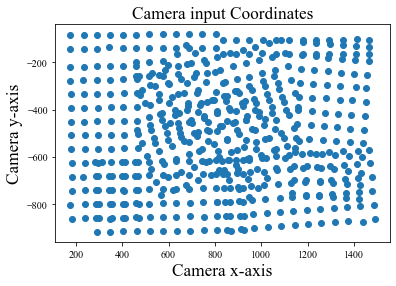

In [9]:
x_in , y_in = input[:,0],input[:,1]
fig, ax = plt.subplots()
ax.set_title("Camera input Coordinates",fontproperties=font)
plt.scatter(x_in,-y_in)
plt.xlabel('Camera x-axis',fontproperties=font)
plt.ylabel('Camera y-axis',fontproperties=font)
# plt.xticks()
# fig.savefig('.\\Camera input Coordinates.eps',format='eps')
plt.show()

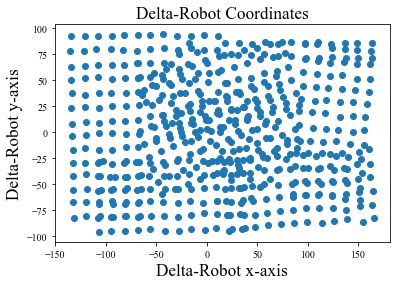

In [10]:
x_out , y_out = output[:,0],output[:,1]
fig, ax = plt.subplots()
ax.set_title('Delta-Robot Coordinates',fontproperties=font)
plt.scatter(x_out,y_out)
plt.xlabel('Delta-Robot x-axis',fontproperties=font)
plt.ylabel('Delta-Robot y-axis',fontproperties=font)
# fig.savefig('.\\Delta-Robot Coordinates.eps',format='eps')
plt.show()

In [11]:
mean_centered_output = output - np.mean(output,axis=0)
mean_centered_output

array([[-118.08608706,  -26.74567431],
       [ 118.41438041,   56.69524721],
       [  14.95891298,   75.15882888],
       ...,
       [ -44.32418819,   80.78768559],
       [ -45.38418819,  -26.20231441],
       [ -12.80418819,   -7.44231441]])

In [12]:
mean_centered_input = input - np.mean(input,axis=0)
mean_centered_input

array([[-515.79749104,  123.2688172 ],
       [ 516.20250896, -257.7311828 ],
       [  63.20250896, -337.7311828 ],
       ...,
       [-195.79749104, -360.7311828 ],
       [-197.79749104,  118.2688172 ],
       [ -55.79749104,   33.2688172 ]])

In [13]:
tr_mat_centered = np.dot(np.linalg.pinv(mean_centered_input),mean_centered_output)
tr_mat_centered

array([[ 0.2287074 , -0.00156808],
       [-0.00125149, -0.22345958]])

In [14]:
offset_found_Centered = np.mean(output - np.dot(input,tr_mat_centered),axis=0)
offset_found_Centered

array([-173.09256444,  111.67354843])

In [15]:
regenerated_output_centered = np.dot(input,tr_mat_centered) + offset_found_Centered

In [16]:
input

array([[ 312.,  624.],
       [1344.,  243.],
       [ 891.,  163.],
       ...,
       [ 632.,  140.],
       [ 630.,  619.],
       [ 772.,  534.]])

In [17]:
np.min((regenerated_output_centered - output),axis=0)

array([-2.64736341, -2.83051106])

In [18]:
np.max((regenerated_output_centered - output),axis=0)

array([2.66126937, 2.97913002])

In [19]:
np.mean((regenerated_output_centered - output),axis=0)

array([ 7.10542736e-15, -5.68796304e-14])

In [20]:
differences = regenerated_output_centered - output

In [21]:
x_out_pred_centered , y_out_pred_centered = differences[:,0],differences[:,1]

In [22]:
distances = np.sqrt((x_out_pred_centered**2)+(y_out_pred_centered**2))
distances.max()

3.037066254454665

In [23]:
distances.mean()

1.2108695658400042

In [24]:
distances.min()

0.036001226249296595

In [25]:
np.median(distances)

1.1004702998450502

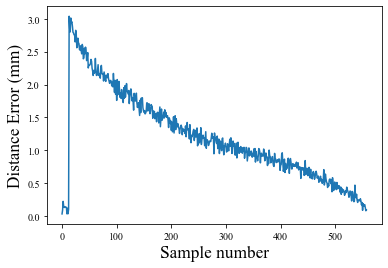

In [26]:
fig, ax = plt.subplots()
# ax.set_title('distances',fontproperties=font)
plt.xlabel('Sample number',fontproperties=font)
plt.ylabel('Distance Error (mm)',fontproperties=font)
plt.plot(distances)
fig.savefig('.\\distances.pdf',format='pdf')
plt.show()

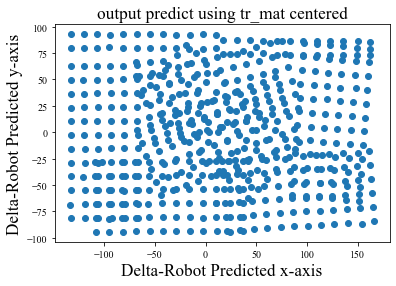

In [28]:
x_out_pred_centered_plot , y_out_pred_centered_plot = regenerated_output_centered[:,0],regenerated_output_centered[:,1]
fig, ax = plt.subplots()
ax.set_title('output predict using tr_mat centered',fontproperties=font)
plt.scatter(x_out_pred_centered_plot,y_out_pred_centered_plot)
plt.xlabel('Delta-Robot Predicted x-axis',fontproperties=font)
plt.ylabel('Delta-Robot Predicted y-axis',fontproperties=font)
# fig.savefig('.\\Delta-Robot Predicted Coordinates.eps',format='eps')
plt.show()

heatmap

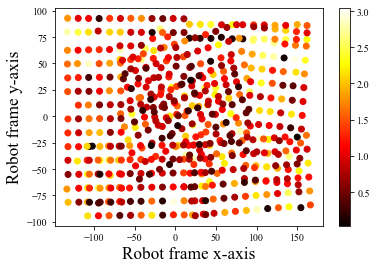

In [30]:
x_out_pred_centered_plot , y_out_pred_centered_plot = regenerated_output_centered[:,0],regenerated_output_centered[:,1]
fig, ax = plt.subplots()
# ax.set_title('Heatmap of Distance between \n predict using tr_mat centered and real Robot output',fontproperties=font)
scat = plt.scatter(x_out_pred_centered_plot,y_out_pred_centered_plot,c=distances,cmap="hot")
plt.xlabel('Robot frame x-axis',fontproperties=font)
plt.ylabel('Robot frame y-axis',fontproperties=font)
plt.colorbar(scat,ax=ax)
fig.savefig('.\\Delta-Robot Predicted Coordinates Heatmap.pdf',format='pdf')
plt.show()

In [51]:
distances.reshape((558,1))

array([[2.73203065],
       [1.31140069],
       [2.54554747],
       [1.21459275],
       [0.73703823],
       [0.52053605],
       [0.32615749],
       [0.52151711],
       [0.35525323],
       [1.26217683],
       [0.98312064],
       [1.42768052],
       [1.54713711],
       [0.96896732],
       [0.91122638],
       [0.97948111],
       [1.20146528],
       [0.88870414],
       [1.49339422],
       [0.57957204],
       [1.16051694],
       [0.79764426],
       [0.91603727],
       [0.8055152 ],
       [0.95703339],
       [0.62473427],
       [0.77766165],
       [1.45283099],
       [0.58890668],
       [0.32605138],
       [0.40103092],
       [1.03652971],
       [2.15500846],
       [1.64652857],
       [2.15870086],
       [0.98652098],
       [0.33147322],
       [0.07627162],
       [1.49799135],
       [2.04266261],
       [1.09224663],
       [1.24309994],
       [2.25687386],
       [2.4505902 ],
       [0.94852535],
       [2.44643693],
       [2.03601939],
       [2.051

In [27]:
pd.DataFrame(dataset)

,0,1,2,3,4,5,6,7
0,312.0,624.0,46.0,176.0,96.0,-102.481899,-28.263360,-442.57
1,1344.0,243.0,46.0,176.0,96.0,134.018569,55.177562,-425.75
2,891.0,163.0,46.0,176.0,96.0,30.563101,73.730574,-429.00
3,833.0,163.0,46.0,176.0,96.0,17.302347,73.820005,-431.05
4,1438.0,877.0,46.0,176.0,96.0,154.594071,-86.464492,-439.32
...,...,...,...,...,...,...,...,...
553,924.0,851.0,46.0,176.0,96.0,37.190000,-79.770000,-440.67
554,298.0,862.0,46.0,176.0,96.0,-106.000000,-81.240000,-443.75
555,632.0,140.0,46.0,176.0,96.0,-28.720000,79.270000,-444.02
556,630.0,619.0,46.0,176.0,96.0,-29.780000,-27.720000,-442.38


In [28]:
new_dataset = np.concatenate((dataset,distances.reshape((558,1))),axis=1)
new_dataset = pd.DataFrame(new_dataset)
new_dataset

,0,1,2,3,4,5,6,7,8
0,312.0,624.0,46.0,176.0,96.0,-102.481899,-28.263360,-442.57,0.036908
1,1344.0,243.0,46.0,176.0,96.0,134.018569,55.177562,-425.75,0.053694
2,891.0,163.0,46.0,176.0,96.0,30.563101,73.730574,-429.00,0.080695
3,833.0,163.0,46.0,176.0,96.0,17.302347,73.820005,-431.05,0.082805
4,1438.0,877.0,46.0,176.0,96.0,154.594071,-86.464492,-439.32,0.063569
...,...,...,...,...,...,...,...,...,...
553,924.0,851.0,46.0,176.0,96.0,37.190000,-79.770000,-440.67,0.145148
554,298.0,862.0,46.0,176.0,96.0,-106.000000,-81.240000,-443.75,0.159848
555,632.0,140.0,46.0,176.0,96.0,-28.720000,79.270000,-444.02,0.065979
556,630.0,619.0,46.0,176.0,96.0,-29.780000,-27.720000,-442.38,0.080709


In [31]:
new_dataset = new_dataset.sort_values(by=8,ascending=False)
input_error = new_dataset[new_dataset[8]>3]
input_error

,0,1,2,3,4,5,6,7,8
5,949.0,163.0,46.0,176.0,96.0,45.68,70.36,-428.54,3.847463
6,1064.0,164.0,46.0,176.0,96.0,71.14,70.01,-429.60,3.460655
7,1005.0,158.0,46.0,176.0,96.0,57.88,71.53,-425.47,3.453613
8,1121.0,164.0,46.0,176.0,96.0,84.37,70.12,-432.25,3.341545
10,1259.0,882.0,46.0,176.0,96.0,111.57,-84.85,-446.57,3.281161
9,295.0,626.0,46.0,176.0,96.0,-106.85,-31.91,-436.65,3.253673
11,1417.0,578.0,46.0,176.0,96.0,147.62,-17.94,-433.73,3.157973
12,948.0,260.0,46.0,176.0,96.0,43.01,55.08,-445.05,3.064969
13,179.0,452.0,46.0,176.0,96.0,-133.31,7.41,-432.50,3.002415


In [89]:
new_dataset.iloc[0:5,5:7]

,5,6
83,-96.55,-29.09
159,135.70,50.76
556,33.81,70.36
557,20.96,71.21
425,151.90,-83.27


In [84]:
regenerated_output_error = np.dot(input_error,tr_mat_centered) + offset_found_Centered
regenerated_output_error

array([[-102.48189887,  -28.2633599 ],
       [ 134.0185686 ,   55.17756162],
       [  30.56310116,   73.73057434],
       [  17.30234746,   73.82000538],
       [ 154.59407132,  -86.46449234]])

In [117]:
new_dataset_new = pd.DataFrame(new_dataset.copy())
new_dataset_new

,0,1,2,3,4,5,6,7,8
83,312.0,624.0,46.0,176.0,96.0,-96.55,-29.09,-442.57,5.989220
159,1344.0,243.0,46.0,176.0,96.0,135.70,50.76,-425.75,4.726739
556,891.0,163.0,46.0,176.0,96.0,33.81,70.36,-429.00,4.680077
557,833.0,163.0,46.0,176.0,96.0,20.96,71.21,-431.05,4.493390
425,1438.0,877.0,46.0,176.0,96.0,151.90,-83.27,-439.32,4.178852
...,...,...,...,...,...,...,...,...,...
140,924.0,851.0,46.0,176.0,96.0,37.19,-79.77,-440.67,0.125034
219,298.0,862.0,46.0,176.0,96.0,-106.00,-81.24,-443.75,0.121935
519,632.0,140.0,46.0,176.0,96.0,-28.72,79.27,-444.02,0.100446
108,630.0,619.0,46.0,176.0,96.0,-29.78,-27.72,-442.38,0.082930


In [118]:
new_dataset_new.iloc[0:5,5:7].values

array([[-96.55, -29.09],
       [135.7 ,  50.76],
       [ 33.81,  70.36],
       [ 20.96,  71.21],
       [151.9 , -83.27]])

In [119]:
new_dataset_new.iloc[0:5,5:7] = new_dataset_new.iloc[0:5,5:7].replace(new_dataset_new.iloc[0:5,5:7].values.flatten(),regenerated_output_error.flatten())

In [115]:
new_dataset_new.iloc[0:5,5:7].values.flatten()

array([-102.48189887,  -28.2633599 ,   55.17756162,  134.0185686 ,
         30.56310116,   73.73057434,   73.82000538,   17.30234746,
        154.59407132,  -86.46449234])

In [121]:
regenerated_output_error

array([[-102.48189887,  -28.2633599 ],
       [ 134.0185686 ,   55.17756162],
       [  30.56310116,   73.73057434],
       [  17.30234746,   73.82000538],
       [ 154.59407132,  -86.46449234]])

In [129]:
np.save('corrected_dataset.npy',np.array(new_dataset_new.iloc[:,0:8]))

In [92]:
new_dataset_new = new_dataset.replace([new_dataset.iloc[0:5,5:7]],pd.DataFrame(regenerated_output_error))
new_dataset_new

ValueError: Replacement lists must match in length. Expecting 1 got 5 